## 가설 3: 발송/운송 소요시간이 배송 지연에 미치는 영향

**가설**: 배송 지연(mi_date)의 원인을 "원인 → 지연 → 결과" 구조로 확장하기 위해, 주문 처리 과정을 두 구간으로 나눠 분석한다.
- 발송 구간(`carrier_lag`): 결제 완료 ~ 판매자가 운송사에 인계
- 운송 구간(`transit_lag`): 운송사 인계 ~ 고객 수령

각 구간의 소요시간이 최종 배송 지연일수(`mi_date`, 실제-예상 배송일 차이)와 얼마나 관련 있는지 상관관계를 확인.

### 3-1. 발송 소요시간(carrier_lag)

**전처리**: 아직 운송사에 인계되지 않은 주문(`order_delivered_carrier_date is null`)은 제외.


In [8]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
with carrier as (select order_delivered_carrier_date
                     , order_purchase_timestamp
                     , julianday(order_delivered_carrier_date) - julianday(order_purchase_timestamp) as carrier_lag
                     , mi_date
              from orders_clean)

select *
from carrier
where order_delivered_carrier_date is not null
"""

df = pd.read_sql(query, conn)
conn.close()

print(df.shape) 

(96187, 4)


In [9]:
from scipy import stats
import matplotlib.pyplot as plt

In [10]:
pearson_corr = df['carrier_lag'].corr(df['mi_date'], method = 'pearson')
print("피어슨 : ", pearson_corr)

피어슨 :  0.19952783663632503


In [11]:
spearman_corr = df['carrier_lag'].corr(df['mi_date'], method = 'spearman')
print("스피어만 : ", spearman_corr)

스피어만 :  0.18430329989370156


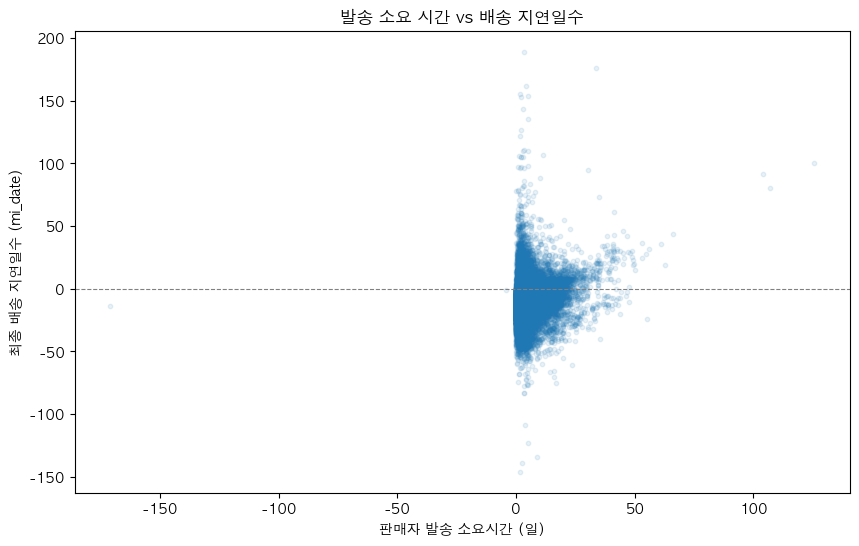

In [12]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# 한글 폰트 설정 
mpl.rcParams['font.family'] = 'AppleGothic'
mpl.rcParams['axes.unicode_minus'] = False  

plt.figure(figsize = (10,6))
plt.scatter(df['carrier_lag'], df['mi_date'], alpha = 0.1, s = 10)
plt.xlabel('판매자 발송 소요시간 (일)')
plt.ylabel('최종 배송 지연일수 (mi_date)')
plt.title('발송 소요 시간 vs 배송 지연일수')
plt.axhline(y = 0, color = 'gray', linestyle = '--', linewidth = 0.8)
plt.show()

**해석**: 발송 소요시간과 지연일수의 상관관계는 약함(Pearson 0.1995, Spearman 0.1843).   
산점도에서도 carrier_lag가 0~10일 근처에 몰려있는 반면 mi_date는 넓게 퍼져있어, 발송이 빨라도 최종 지연 여부는 다양하게 갈리는 것을 확인함   
→ 발송 속도만으로는 지연을 설명하기 부족함.

### 3-2. 운송 소요시간(transit_lag)

**전처리**: 운송사 인계일보다 고객 수령일이 빠르게 기록된, 데이터 오류로 추정되는 음수 `transit_lag` 행을 `transit_lag > 0` 조건으로 제외.


In [13]:
conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
with transit as (select order_delivered_customer_date
										  , order_delivered_carrier_date
										  , julianday(order_delivered_customer_date) - julianday(order_delivered_carrier_date) as transit_lag
                                          , mi_date
								from orders_clean)

	
select *
from transit 
where transit_lag > 0 
"""

df2 = pd.read_sql(query, conn)
conn.close()

df2.shape

(96155, 4)

In [14]:
pearson_corr2 = df2['transit_lag'].corr(df2['mi_date'], method='pearson')
print("피어슨 (운송구간):", pearson_corr2)

spearman_corr2 = df2['transit_lag'].corr(df2['mi_date'], method='spearman')
print("스피어만 (운송구간):", spearman_corr2)

피어슨 (운송구간): 0.5528895252643808
스피어만 (운송구간): 0.23304422116586687


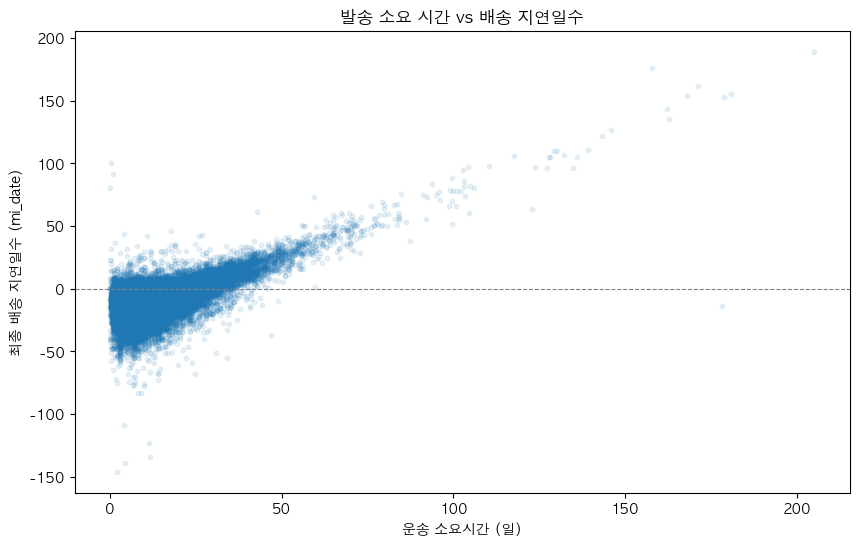

In [15]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# 한글 폰트 설정 
mpl.rcParams['font.family'] = 'AppleGothic'
mpl.rcParams['axes.unicode_minus'] = False  

plt.figure(figsize = (10,6))
plt.scatter(df2['transit_lag'], df2['mi_date'], alpha = 0.1, s = 10)
plt.xlabel('운송 소요시간 (일)')
plt.ylabel('최종 배송 지연일수 (mi_date)')
plt.title('발송 소요 시간 vs 배송 지연일수')
plt.axhline(y = 0, color = 'gray', linestyle = '--', linewidth = 0.8)
plt.show()

**해석**: 운송 소요시간과 지연일수는 강한 상관관계(Pearson 0.5529, Spearman 0.2330).   
산점도에서 transit_lag가 100일을 넘는 극단값 구간에서 거의 선형에 가까운 관계가 나타나 Pearson 값을 끌어올린 것으로 보임.   
극단값(35건)을 seller_id, customer_state 기준으로 확인했으나 특정 판매자나 지역에 집중되는 패턴은 없었고, 개별 물류 사고에 가까운 것으로 해석함(구조적 원인이라기보다 예측 불가한 이상 상황).

**가설 3 결론**: 발송 소요시간은 지연에 미치는 영향이 약하고, 운송 소요시간이 지연의 핵심 원인으로 확인됨.

## 가설 4: 판매자-고객 거리가 배송 지연에 미치는 영향

**가설**: 판매자와 고객 사이의 물리적 거리(distance_km)가 멀수록 배송이 더 지연될 것이다.

**전처리**:
- `geolocation` 테이블은 우편번호 프리픽스(zip_code_prefix)당 위경도가 여러 개 매핑되어 있어, 프리픽스별 평균 위경도로 집계한 `geo_clean` 테이블을 별도로 생성해 사용
- 고객·판매자 우편번호 프리픽스로 조인해 좌표를 가져온 뒤, Haversine 공식으로 두 지점 간 실제 거리(km)를 계산


In [16]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
select o.order_id as order_id
	, oi.seller_id as seller_id
	, gc.lat as customer_lat
	, gc.lng as customer_lng
	, gs.lat as seller_lat
	, gs.lng as seller_lng
from orders_clean o join customers c on o.customer_id = c.customer_id
					join geo_clean gc on c.customer_zip_code_prefix = gc.zip_prefix
					join order_items oi on o.order_id = oi.order_id
					join sellers s on oi.seller_id = s.seller_id
					join geo_clean gs on s.seller_zip_code_prefix = gs.zip_prefix
"""

df = pd.read_sql(query, conn)
conn.close()

print(df.shape) 

(109338, 6)


In [17]:
import numpy as np

def haversine(lat1, lng1, lat2, lng2):
    R = 6371  # 지구 반지름(km)
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat = lat2 - lat1
    dlng = lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

df['distance_km'] = haversine(df['customer_lat'], df['customer_lng'], df['seller_lat'], df['seller_lng'])

print(df['distance_km'].describe())

count    109338.000000
mean        595.483560
std         587.023587
min           0.000000
25%         184.562433
50%         431.596062
75%         790.638900
max        3399.190906
Name: distance_km, dtype: float64


In [18]:
df.sort_values('distance_km', ascending=False).head(10)

,order_id,seller_id,customer_lat,customer_lng,seller_lat,seller_lng,distance_km
47993,9b790ca446b8e28ce5e4382959f6b7df,1cbd50a8c52e6cf8e315c5709fab386f,2.822592,-60.754147,-25.673177,-49.328012,3399.190906
41966,2889d7816934298a0f5a4a30ef3ffbc7,b90e891671cffd9557f33a97dc523645,2.811251,-60.678297,-25.542326,-49.182195,3387.360474
30,ecab90c9933c58908d3d6add7c6f5ae3,f7720c4fa8e3aba4546301ab80ea1f1b,2.822592,-60.754147,-25.501031,-49.333140,3381.363478
16157,be5cae366c82f548c9a28b353ab44dd0,c840d3fdbba0790404fdae73d253b253,2.835272,-60.673422,-25.461016,-49.231064,3379.425930
16158,be5cae366c82f548c9a28b353ab44dd0,c840d3fdbba0790404fdae73d253b253,2.835272,-60.673422,-25.461016,-49.231064,3379.425930
66538,714f94b6231908bda17ea75f8f9e7c11,06a2c3af7b3aee5d69171b0e14f0ee87,-31.759922,-52.235542,-2.501242,-44.248163,3359.272086
50936,f77eb63e272ad822e11bbf97da9c0edd,d91fb3b7d041e83b64a00a3edfb37e4f,2.832975,-60.665785,-24.026526,-46.478237,3357.862304
44632,cedca39b10d8d496f77547b16e2dbf56,48985c61529077fa4f1e38bcff0f2ed3,0.035666,-51.063103,-30.030589,-51.227697,3343.260551
38137,14c9f30dcfd7bff68d5663ce8626cc19,94144541854e298c2d976cb893b81343,-0.025469,-51.174201,-30.077761,-51.053306,3341.686896
93568,d3f9832594bb9037370cdf8bdcd052cd,87142160b41353c4e5fca2360caf6f92,0.016429,-51.082907,-30.008182,-51.201304,3338.607866


In [22]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
select o.order_id
     , oi.seller_id
     , o.mi_date
     , gc.lat as customer_lat
     , gc.lng as customer_lng
     , gs.lat as seller_lat
     , gs.lng as seller_lng
from orders_clean o 
join customers c on o.customer_id = c.customer_id
join geo_clean gc on c.customer_zip_code_prefix = gc.zip_prefix
join order_items oi on o.order_id = oi.order_id
join sellers s on oi.seller_id = s.seller_id
join geo_clean gs on s.seller_zip_code_prefix = gs.zip_prefix
"""

df = pd.read_sql(query, conn)
conn.close()

print(df.shape)

(109338, 7)


In [23]:
df['distance_km'] = haversine(df['customer_lat'], df['customer_lng'], df['seller_lat'], df['seller_lng'])

print(df['distance_km'].describe())

count    109338.000000
mean        595.483560
std         587.023587
min           0.000000
25%         184.562433
50%         431.596062
75%         790.638900
max        3399.190906
Name: distance_km, dtype: float64


**전처리 이슈**: 하나의 주문(order_id)에 판매자가 여러 명 포함된 경우(다중 판매자 주문) 거리가 여러 개 계산되므로, 주문당 거리가 가장 큰 값을 대표값으로 선택해 order_id 기준 1건으로 정리.

In [24]:
# 각 order_id 그룹에서 distance_km이 가장 큰 row의 인덱스 찾기
idx = df.groupby('order_id')['distance_km'].idxmax()

# 그 인덱스에 해당하는 row만 남기기
df_rep = df.loc[idx].reset_index(drop=True)

print(df_rep.shape)

(95712, 8)


In [26]:
pearson_corr3 = df_rep['distance_km'].corr(df_rep['mi_date'], method='pearson')
print("피어슨 (거리):", pearson_corr3)

spearman_corr3 = df_rep['distance_km'].corr(df_rep['mi_date'], method='spearman')
print("스피어만 (거리):", spearman_corr3)

피어슨 (거리): -0.08557664895828263
스피어만 (거리): -0.18266138377788277


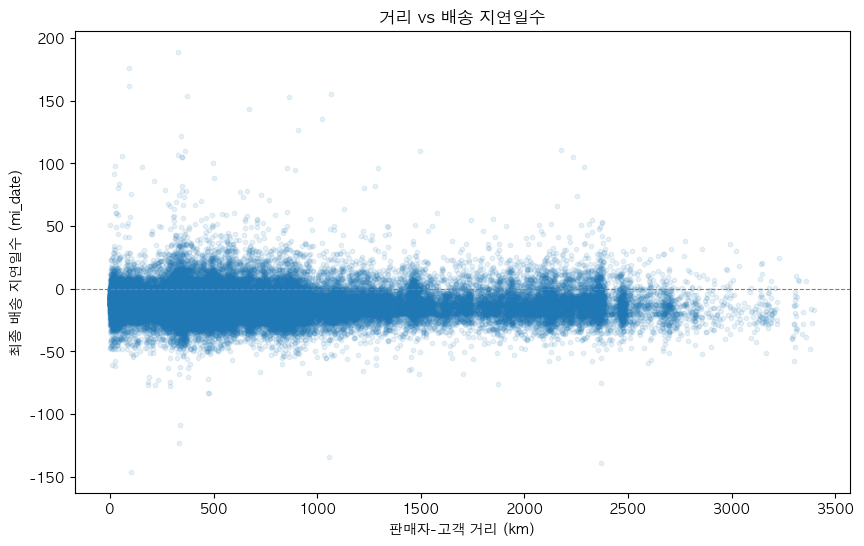

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df_rep['distance_km'], df_rep['mi_date'], alpha=0.1, s=10)
plt.xlabel('판매자-고객 거리 (km)')
plt.ylabel('최종 배송 지연일수 (mi_date)')
plt.title('거리 vs 배송 지연일수')
plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
plt.show()

**해석**: 거리(distance_km)와 지연일수(mi_date)는 약한 음의 상관관계(Pearson -0.09, Spearman -0.18)로, "거리가 멀수록 지연이 준다"는 역설적인 결과가 나옴.  
이 역설의 원인을 확인하기 위해 거리와 예상 배송 소요일(estimated_days)의 관계를 추가로 살펴봄.


In [32]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
select order_id
     , julianday(order_estimated_delivery_date) - julianday(order_purchase_timestamp) as estimated_days
from orders_clean
"""

df_est = pd.read_sql(query, conn)
conn.close()

df_rep2 = df_rep.merge(df_est, on='order_id', how='left')

print(df_rep2.shape)
print(df_rep2['estimated_days'].describe())

(95712, 9)
count    95712.000000
mean        23.735464
std          8.772471
min          2.008009
25%         18.320854
50%         23.229566
75%         28.411806
max        155.135463
Name: estimated_days, dtype: float64


In [33]:
pearson_est = df_rep2['distance_km'].corr(df_rep2['estimated_days'], method='pearson')
print("피어슨 (거리 vs 예상소요일):", pearson_est)

spearman_est = df_rep2['distance_km'].corr(df_rep2['estimated_days'], method='spearman')
print("스피어만 (거리 vs 예상소요일):", spearman_est)

피어슨 (거리 vs 예상소요일): 0.516842068578896
스피어만 (거리 vs 예상소요일): 0.6183727555875783


**해석**: 거리와 예상 배송 소요일은 강한 양의 상관관계(Pearson 0.5168, Spearman 0.6184) — Olist가 거리가 멀수록 예상 배송일 자체를 넉넉하게 설정해준다는 뜻.

**가설 4 결론**: 거리가 멀어질수록 실제 운송 시간은 늘어나지만, 예상 배송일 산정 방식이 거리를 이미 반영해 넉넉하게 잡아주기 때문에 "기대 대비 지연"을 나타내는 상대지표(mi_date)에는 오히려 거리가 완충 작용을 하는 것으로 해석됨.   
즉 거리가 지연을 실제로 줄이는 것이 아니라, 예상치 산정 방식이 지연 여부 판단을 상쇄시키는 것.


In [34]:
df_rep2.to_csv('/Users/gon-i/Desktop/tableau_distance.csv', index=False)